## 1. Hugging Face Login

#### This imports the token from Kaggle Secrets, so make sure the secret is set correctly before running the code.

In [4]:
import os
from huggingface_hub import login
from kaggle_secrets import UserSecretsClient

user_secrets = UserSecretsClient()
HF_TOKEN = user_secrets.get_secret("hf_token_rp")
os.environ["HF_TOKEN"] = HF_TOKEN
login(token=HF_TOKEN)

print("Hugging Face login successful.")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Hugging Face login successful.


## 2. Check GPU

In [2]:
import torch

print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    print(f"GPU {i}:", torch.cuda.get_device_name(i))

CUDA available: True
GPU count: 2
GPU 0: Tesla T4
GPU 1: Tesla T4


## 3. Configuration

#### this is sample configuration, you are free to modify any parameter to train the best performing model

In [5]:
import os
import random
import json
import time
import math
import zipfile
import shutil

# Hugging Face dataset
HF_DATASET_REPO = "Exploration-Lab/CS-781-Capstone"

# You can use any of the 4 train files or all the files for pre-training the legal model
TRAIN_FILE0 = "Phase_1_Pretraining/Train/train_supreme_court.json"
TRAIN_FILE1 = "Phase_1_Pretraining/Train/train_high_courts.json"
TRAIN_FILE2 = "Phase_1_Pretraining/Train/train_acts.json"
TRAIN_FILE3 = "Phase_1_Pretraining/Train/train_tribunals.json"

TEST_FILE = "Phase_1_Pretraining/Test/test.json"

# Training configuration
TRAIN_TOKENS = 200_000_000
VAL_TOKENS = 5_000_000
TRAIN_BLOCK_SIZE = 2048
EPOCHS = 3
SEED = 42
random.seed(SEED)
MODEL_CONTEXT_LENGTH = 2048
N_EMBD = 640
N_LAYER = 8
N_HEAD = 8

# Generation
TARGET_GENERATION_WORDS = 128
MAX_GENERATION_TOKENS = 384
TEMPERATURE = 0.1
TOP_P = 0.95

# Kaggle output
OUTPUT_DIR = "/kaggle/working/cs781_phase1"
MODEL_OUTPUT_DIR = os.path.join(
    OUTPUT_DIR,
    "legal-cnn-attention-final"
)
PREDICTION_PATH = os.path.join(
    OUTPUT_DIR,
    "prediction.json"
)
SUBMISSION_ZIP = os.path.join(
    OUTPUT_DIR,
    "submission.zip"
)
LOSS_PLOT_PATH = os.path.join(
    OUTPUT_DIR,
    "training_validation_loss.png"
)
os.makedirs(
    OUTPUT_DIR,
    exist_ok=True
)
print("Configuration loaded.")

# ------------------------------------------------------------
# Run-mode switches
# ------------------------------------------------------------
# False: load the saved BPE tokenizer used for every submission (recommended).
# True : retrain the BPE tokenizer from the corpus (slow, pure Python).
TRAIN_NEW_TOKENIZER = False
TOKENIZER_INPUT_PATH = "/kaggle/input/datasets/sg123321/tokenize/legal_bpe.json"

# Optional pre-tokenized corpus (train/val token arrays). If it is not attached,
# the mixed corpus is built and tokenized in this notebook and cached in OUTPUT_DIR.
TOKENIZED_CACHE_INPUT = "/kaggle/input/datasets/sg123321/tokenize/tokenized_data.npz"

# Full-corpus token statistics (used for the report). Very slow; off by default.
COUNT_CORPUS_TOKENS = False

# Resume a Trainer checkpoint, e.g. "/kaggle/input/datasets/sg123321/finalcnn1"
# (the run used for the submission). None trains from random initialization.
RESUME_FROM_CHECKPOINT = None


Configuration loaded.


## 4. Download Training Data From Hugging Face

In [ ]:
from huggingface_hub import hf_hub_download

# Download all four training files
TRAIN_FILES = {
    "supreme_court": hf_hub_download(
        repo_id=HF_DATASET_REPO,
        filename=TRAIN_FILE0,
        repo_type="dataset"
    ),
    "high_courts": hf_hub_download(
        repo_id=HF_DATASET_REPO,
        filename=TRAIN_FILE1,
        repo_type="dataset"
    ),
    "acts": hf_hub_download(
        repo_id=HF_DATASET_REPO,
        filename=TRAIN_FILE2,
        repo_type="dataset"
    ),
    "tribunals": hf_hub_download(
        repo_id=HF_DATASET_REPO,
        filename=TRAIN_FILE3,
        repo_type="dataset"
    )
}

for source, path in TRAIN_FILES.items():
    print(f"{source}: {path}")

## 5. Load Tokenizer

In [55]:
# from transformers import AutoTokenizer

# tokenizer = AutoTokenizer.from_pretrained("openai-community/gpt2")
# tokenizer.pad_token = tokenizer.eos_token
# print("Vocabulary size:", len(tokenizer))

#BPE tokenizer

def train_tokenizer(train_text, vocab_size):
    tokenizer = ByteLevelBPE(vocab_size=vocab_size)
    tokenizer.train([train_text])
    return tokenizer

# ============================================================
# QUESTION 5 — OPTIMIZED BYTE-LEVEL BPE
# ============================================================

import json
from collections import Counter, defaultdict
from tqdm.auto import tqdm


BPE_SPECIALS = [
    "<pad>",
    "<unk>",
    "<s>",
    "</s>"
]

# End-of-word marker.
# UTF-8 bytes are integers 0..255, so 256 cannot collide.
EOW = 256


class ByteLevelBPE:
    """
    Deterministic byte-level BPE tokenizer.

    - Initial units are UTF-8 bytes.
    - EOW marks the end of each word.
    - Case is preserved.
    - BPE never crosses word boundaries.
    - Ties are broken lexicographically.
    - Four special tokens are fixed at the beginning.
    """

    def __init__(self, vocab_size=5000):

        self.vocab_size = vocab_size
        self.merge_ranks = {}
        self.specials = list(BPE_SPECIALS)

        # List of learned merges.
        #
        # Each element is:
        #     (left_symbol, right_symbol)
        #
        self.merges = []

        # Vocabulary.
        self.itos = []
        self.stoi = {}

        # Internal merge rules.
        #
        # (left, right) -> merged_symbol
        #
        self.merge_rules = {}

        # Final representations of words seen during training.
        self.word_cache = {}
        self.token_to_symbol = {}

    # --------------------------------------------------------
    # Convert a byte/symbol tuple into a deterministic string
    # --------------------------------------------------------
    @staticmethod
    def string_to_symbol(token):
        # Standalone end-of-word marker
        if token == "</w>":
            return (EOW,)
    
        # Merged symbol ending with EOW
        if token.endswith("</w>>"):
            hex_part = token[3:-5]
            byte_part = tuple(
                int(hex_part[i:i+2], 16)
                for i in range(0, len(hex_part), 2)
            )
            return byte_part + (EOW,)
    
        # Ordinary byte or merged byte symbol
        hex_part = token[3:-1]
        return tuple(
            int(hex_part[i:i+2], 16)
            for i in range(0, len(hex_part), 2)
        )
    @staticmethod
    def symbol_to_string(symbol):

        # EOW is always the last symbol when present.
        if symbol and symbol[-1] == EOW:

            byte_part = symbol[:-1]

            if len(byte_part) == 0:
                return "</w>"

            hex_part = "".join(
                f"{b:02x}"
                for b in byte_part
            )

            return f"<0x{hex_part}</w>>"

        hex_part = "".join(
            f"{b:02x}"
            for b in symbol
        )

        return f"<0x{hex_part}>"
    def _build_merge_ranks(self):
        self.merge_ranks = {
            pair: rank
            for rank, pair in enumerate(self.merge_rules)
        }
    # --------------------------------------------------------
    # Deterministic ordering key for symbols
    # --------------------------------------------------------

    @staticmethod
    def symbol_key(symbol):
        return tuple(symbol)

    # --------------------------------------------------------
    # Convert a word into initial UTF-8 byte symbols
    # --------------------------------------------------------

    @staticmethod
    def word_to_symbols(word):

        byte_values = list(
            word.encode("utf-8")
        )

        symbols = [
            (b,)
            for b in byte_values
        ]

        # Explicit word boundary.
        symbols.append((EOW,))

        return symbols

    # --------------------------------------------------------
    # Count all pairs once initially
    # --------------------------------------------------------

    def _initial_pair_counts(
        self,
        word_symbols,
        word_counts
    ):

        pair_counts = Counter()

        # pair_words tells us which words contain a pair.
        pair_words = defaultdict(set)

        for word, symbols in word_symbols.items():

            freq = word_counts[word]

            for i in range(len(symbols) - 1):

                pair = (
                    symbols[i],
                    symbols[i + 1]
                )

                pair_counts[pair] += freq
                pair_words[pair].add(word)

        return pair_counts, pair_words

    # --------------------------------------------------------
    # Merge one pair in one word
    # --------------------------------------------------------

    @staticmethod
    def _merge_word(symbols, pair):

        left, right = pair

        new_symbol = left + right

        result = []

        i = 0

        while i < len(symbols):

            if (
                i + 1 < len(symbols)
                and symbols[i] == left
                and symbols[i + 1] == right
            ):

                result.append(new_symbol)

                i += 2

            else:

                result.append(symbols[i])

                i += 1

        return result

    # --------------------------------------------------------
    # Train
    # --------------------------------------------------------

    def train(self, texts):

        print("=" * 70)
        print("Training BYTE-LEVEL BPE")
        print("=" * 70)

        # ----------------------------------------------------
        # Count unique words.
        # ----------------------------------------------------

        word_counts = Counter()

        for text in texts:
            if not isinstance(text, str):
                continue

            for word in text.split():

                word_counts[word] += 1

        print(
            f"Unique words: {len(word_counts):,}"
        )

        # ----------------------------------------------------
        # Initial representation of each word.
        # ----------------------------------------------------

        word_symbols = {
            word: self.word_to_symbols(word)
            for word in word_counts
        }

        # ----------------------------------------------------
        # Initial vocabulary symbols.
        # ----------------------------------------------------

        initial_symbols = [
            (b,)
            for b in range(256)
        ]

        initial_symbols.append((EOW,))

        # Four specials + initial byte symbols.
        current_vocab_size = (
            len(BPE_SPECIALS)
            + len(initial_symbols)
        )

        print(
            f"Initial vocabulary size: "
            f"{current_vocab_size:,}"
        )

        if current_vocab_size > self.vocab_size:

            raise ValueError(
                "Initial byte vocabulary already exceeds "
                "the requested vocabulary size."
            )

        # ----------------------------------------------------
        # Count pairs once.
        # ----------------------------------------------------

        pair_counts, pair_words = \
            self._initial_pair_counts(
                word_symbols,
                word_counts
            )

        # ----------------------------------------------------
        # Main BPE loop.
        # ----------------------------------------------------

        merge_no = 0

        while current_vocab_size < self.vocab_size:

            if not pair_counts:
                break

            # Ignore pairs occurring only once.
            valid_pairs = [
                pair
                for pair, count in pair_counts.items()
                if count > 1
            ]

            if not valid_pairs:
                print(
                    "No pair occurs more than once. "
                    "Stopping early."
                )
                break

            # Highest frequency first.
            # Lexicographically smallest pair on ties.
            best_pair = min(
                valid_pairs,
                key=lambda pair: (
                    -pair_counts[pair],
                    self.symbol_key(pair[0]),
                    self.symbol_key(pair[1])
                )
            )

            best_count = pair_counts[best_pair]

            left, right = best_pair
            new_symbol = left + right

            # ------------------------------------------------
            # Record merge.
            # ------------------------------------------------

            self.merge_rules[best_pair] = new_symbol

            self.merges.append(
                (
                    self.symbol_to_string(left),
                    self.symbol_to_string(right)
                )
            )

            # ------------------------------------------------
            # Words affected by this merge.
            # ------------------------------------------------

            affected_words = list(
                pair_words.get(best_pair, set())
            )

            # Remove the selected pair's old contribution.
            del pair_counts[best_pair]

            pair_words.pop(
                best_pair,
                None
            )

            # ------------------------------------------------
            # Update each affected word.
            # ------------------------------------------------

            for word in affected_words:

                old_symbols = word_symbols[word]

                old_pairs = []

                for i in range(
                    len(old_symbols) - 1
                ):

                    old_pairs.append(
                        (
                            old_symbols[i],
                            old_symbols[i + 1]
                        )
                    )

                # Remove old pair contributions.
                freq = word_counts[word]

                for pair in old_pairs:

                    pair_counts[pair] -= freq

                    if pair_counts[pair] <= 0:
                        pair_counts.pop(
                            pair,
                            None
                        )

                    if pair in pair_words:
                        pair_words[pair].discard(word)

                        if not pair_words[pair]:
                            pair_words.pop(
                                pair,
                                None
                            )

                # Perform merge.
                new_symbols = self._merge_word(
                    old_symbols,
                    best_pair
                )

                word_symbols[word] = new_symbols

                # Add new pair contributions.
                new_pairs = []

                for i in range(
                    len(new_symbols) - 1
                ):

                    new_pairs.append(
                        (
                            new_symbols[i],
                            new_symbols[i + 1]
                        )
                    )

                for pair in new_pairs:

                    pair_counts[pair] += freq
                    pair_words[pair].add(word)

            current_vocab_size += 1
            merge_no += 1

            if merge_no % 250 == 0:

                print(
                    f"Merges: {merge_no:4d} | "
                    f"Vocab: {current_vocab_size:5d} | "
                    f"Best pair frequency: {best_count:,}"
                )

        # ----------------------------------------------------
        # Construct final vocabulary.
        #
        # First:
        #   <pad>, <unk>, <s>, </s>
        #
        # Then initial symbols.
        #
        # Then symbols introduced by merges in merge order.
        # ----------------------------------------------------

        merged_symbols = list(
            self.merge_rules.values()
        )

        self.itos = (
            list(BPE_SPECIALS)
            +
            [
                self.symbol_to_string(s)
                for s in initial_symbols
            ]
            +
            [
                self.symbol_to_string(s)
                for s in merged_symbols
            ]
        )

        self.token_to_symbol = {}

        for symbol in initial_symbols:
            token = self.symbol_to_string(symbol)
            self.token_to_symbol[token] = symbol

        for symbol in merged_symbols:
            token = self.symbol_to_string(symbol)
            self.token_to_symbol[token] = symbol

        # Remove duplicates while preserving order.
        final_itos = []
        seen = set()

        for token in self.itos:

            if token not in seen:

                seen.add(token)
                final_itos.append(token)

        self.itos = final_itos[
            :self.vocab_size
        ]

        self.stoi = {
            token: i
            for i, token in enumerate(self.itos)
        }

        # Save representations of training words.
        self.word_cache = word_symbols

        print(
            "\nTraining complete."
        )

        print(
            f"Final vocabulary size: "
            f"{len(self.itos):,}"
        )

        print(
            f"Number of merges: "
            f"{len(self.merges):,}"
        )
        self._build_merge_ranks()
        return self

    # --------------------------------------------------------
    # Tokenize a word
    # --------------------------------------------------------

    def tokenize_word(self, word):
        # Use cached representation for training words.
        if word in self.word_cache:
            symbols = self.word_cache[word]
        else:
            symbols = self.word_to_symbols(word)
    
            while len(symbols) > 1:
                # Find adjacent pairs that have learned merges.
                candidates = [
                    (self.merge_ranks[(symbols[i], symbols[i + 1])], i)
                    for i in range(len(symbols) - 1)
                    if (symbols[i], symbols[i + 1]) in self.merge_ranks
                ]
    
                if not candidates:
                    break
    
                # Apply the earliest learned merge.
                _, best_idx = min(candidates)
    
                pair = (symbols[best_idx], symbols[best_idx + 1])
                new_symbol = self.merge_rules[pair]
    
                # Merge all non-overlapping occurrences.
                symbols = self._merge_word(symbols, pair)
    
        return [
            self.symbol_to_string(symbol)
            for symbol in symbols
        ]

    # --------------------------------------------------------
    # Tokenize complete sentence
    # --------------------------------------------------------

    def tokenize(self, text):

        tokens = []

        for word in text.split():

            tokens.extend(
                self.tokenize_word(word)
            )

        return tokens

    def encode(self, text):
        tokens = self.tokenize(text)

        ids = []
        for token in tokens:
            if token in self.stoi:
                ids.append(self.stoi[token])
            else:
                # unknown token
                ids.append(self.stoi["<unk>"])

        return ids

    def decode(self, ids):
      byte_values = []

      for idx in ids:
          token = self.itos[idx]

          if token in BPE_SPECIALS:
              continue

          symbol = self.token_to_symbol[token]

          for b in symbol:
              if b == EOW:
                  byte_values.append(ord(" "))
              else:
                  byte_values.append(b)

      # Remove the final space
      if byte_values and byte_values[-1] == ord(" "):
          byte_values.pop()

      return bytes(byte_values).decode(
            "utf-8",
            errors="ignore"
        )

    @classmethod
    def load(cls, path):
        with open(path, "r", encoding="utf-8") as f:
            data = json.load(f)
    
        tokenizer = cls(vocab_size=data["vocab_size"])
        tokenizer.merges = data["merges"]
        tokenizer.itos = data["itos"]
        tokenizer.stoi = {
            token: i for i, token in enumerate(tokenizer.itos)
        }
    
        # Initial symbols
        initial_symbols = [(b,) for b in range(256)]
        initial_symbols.append((EOW,))
    
        tokenizer.token_to_symbol = {
            tokenizer.symbol_to_string(symbol): symbol
            for symbol in initial_symbols
        }
    
        # Reconstruct merge rules in training order
        for left_str, right_str in tokenizer.merges:
            left = tokenizer.string_to_symbol(left_str)
            right = tokenizer.string_to_symbol(right_str)
            merged = left + right
    
            tokenizer.merge_rules[(left, right)] = merged
            merged_str = tokenizer.symbol_to_string(merged)
            tokenizer.token_to_symbol[merged_str] = merged
        tokenizer._build_merge_ranks()  
        return tokenizer

    # --------------------------------------------------------
    # Save
    # --------------------------------------------------------

    def save(self, path):

        data = {
            "merges": self.merges,
            "itos": self.itos,
            "vocab_size": self.vocab_size
        }

        with open(
            path,
            "w",
            encoding="utf-8"
        ) as f:

            json.dump(
                data,
                f,
                ensure_ascii=False
            )

        print(
            f"Saved: {path}"
        )

# if __name__ == "__main__":
#     train_text = """
#     Harry went to Hogwarts.
#     Harry met Ron and Hermione.
#     Hogwarts was a magical school.
#     """

#     tokenizer = train_tokenizer(train_text, 5000)

#     print("Vocab size:", tokenizer.vocab_size)

#     text = "Harry went to Hogwarts."

#     ids = tokenizer.encode(text)
#     decoded = tokenizer.decode(ids)

#     print("Text:", text)
#     print("IDs:", ids)
#     print("Decoded:", decoded)
#     print("Match:", text == decoded)


In [ ]:
!pip install ijson
import os
import ijson

# ------------------------------------------------------------
# Configuration
# ------------------------------------------------------------

VOCAB_SIZE = 16000
MAX_CHARS_PER_SOURCE = 5_000_000

TOKENIZER_PATH = os.path.join(
    OUTPUT_DIR, "legal_bpe.json"
)


# ------------------------------------------------------------
# Extract text from a record
# ------------------------------------------------------------

def get_text(record):
    if isinstance(record, str):
        return record

    if isinstance(record, dict):
        for key in [
            "text", "content", "judgment",
            "document", "full_text", "body"
        ]:
            if isinstance(record.get(key), str):
                return record[key]

    raise ValueError(
        f"Unable to extract text. Record type: {type(record)}"
    )


# ------------------------------------------------------------
# Stream text from JSON files
# ------------------------------------------------------------

def iter_texts(file_path):
    with open(file_path, "rb") as f:
        for record in ijson.items(f, "item"):
            text = get_text(record)
            if text.strip():
                yield text


# ------------------------------------------------------------
# Create bounded training sample
# ------------------------------------------------------------

def all_documents():
    for source, path in TRAIN_FILES.items():
        print(f"Processing {source}...")

        total_chars = 0

        for text in iter_texts(path):
            remaining = MAX_CHARS_PER_SOURCE - total_chars

            if remaining <= 0:
                break

            text = text[:remaining]

            if text.strip():
                yield text
                total_chars += len(text)

        print(f"{source}: {total_chars:,} characters")


# ------------------------------------------------------------
# Train and save tokenizer
# ------------------------------------------------------------

if TRAIN_NEW_TOKENIZER:
    tokenizer = ByteLevelBPE(vocab_size=VOCAB_SIZE)
    tokenizer.train(all_documents())

    tokenizer.save(TOKENIZER_PATH)

    print(f"Tokenizer saved at: {TOKENIZER_PATH}")

In [56]:
# Load the tokenizer: the one trained above, or the saved tokenizer used for the submissions.
tokenizer = ByteLevelBPE.load(
    TOKENIZER_PATH if TRAIN_NEW_TOKENIZER else TOKENIZER_INPUT_PATH
)

print("Vocabulary size:", len(tokenizer.itos))
print("Number of merges:", len(tokenizer.merges))

# Special-token ids (needed by the corpus tokenization step below).
PAD_ID = tokenizer.stoi["<pad>"]   # 0
UNK_ID = tokenizer.stoi["<unk>"]   # 1
BOS_ID = tokenizer.stoi["<s>"]     # 2
EOS_ID = tokenizer.stoi["</s>"]    # 3


Vocabulary size: 16000
Number of merges: 15739


In [ ]:
import json
from tqdm.auto import tqdm
from pathlib import Path

# ------------------------------------------------------------
# Count tokens in one source
# ------------------------------------------------------------


def count_source_tokens(tokenizer, file_path):
    total_tokens = 0
    total_docs = 0
    total_chars = 0

    for text in tqdm(
        iter_texts(file_path),
        desc=Path(file_path).name
    ):
        ids = tokenizer.encode(text)

        total_tokens += len(ids)
        total_docs += 1
        total_chars += len(text)

        del ids

    return {
        "documents": total_docs,
        "characters": total_chars,
        "tokens": total_tokens,
    }


# ------------------------------------------------------------
# Count tokens in all sources
# ------------------------------------------------------------

def count_all_sources(tokenizer):
    results = {}

    for source, file_path in TRAIN_FILES.items():
        print(f"\nCounting {source}...")
        results[source] = count_source_tokens(
            tokenizer, file_path
        )

    return results


# ------------------------------------------------------------
# Print and save statistics
# ------------------------------------------------------------

def save_and_print_counts(results, output_path="token_counts.json"):
    total_tokens = sum(
        stats["tokens"] for stats in results.values()
    )

    print("\n" + "=" * 75)
    print(
        f"{'Source':<20}{'Documents':>15}"
        f"{'Characters':>18}{'Tokens':>18}"
    )
    print("=" * 75)

    for source, stats in results.items():
        print(
            f"{source:<20}"
            f"{stats['documents']:>15,}"
            f"{stats['characters']:>18,}"
            f"{stats['tokens']:>18,}"
        )

    print("=" * 75)
    print(f"{'TOTAL':<20}{'':>15}{'':>18}{total_tokens:>18,}")

    with open(output_path, "w") as f:
        json.dump(
            {
                "sources": results,
                "total_tokens": total_tokens,
            },
            f,
            indent=2,
        )

    print(f"\nStatistics saved to {output_path}")


# ------------------------------------------------------------
# Run
# ------------------------------------------------------------
tokenizer._build_merge_ranks()
if COUNT_CORPUS_TOKENS:
    results = count_all_sources(tokenizer)
    save_and_print_counts(results)
else:
    print("Skipped full-corpus token counting (COUNT_CORPUS_TOKENS=False).")

In [57]:
def run_tokenizer_checks(tokenizer):
    print("Vocabulary size:", len(tokenizer.itos))
    assert len(tokenizer.itos) == len(tokenizer.stoi)
    assert len(tokenizer.itos) <= tokenizer.vocab_size

    # Symbol serialization round trips
    symbols = [
        (97,),
        (97, 98),
        (97, 98, EOW),
        (EOW,),
        (240, 159, 152, 128, EOW),
    ]

    for symbol in symbols:
        encoded = tokenizer.symbol_to_string(symbol)
        decoded = tokenizer.string_to_symbol(encoded)
        assert decoded == symbol, (symbol, encoded, decoded)

    # Text round trips: your current tokenizer normalizes whitespace.
    tests = [
        "The Supreme Court held that the appeal is allowed.",
        "Section 302 of the Indian Penal Code.",
        "Article 14 and Article 21.",
        "A.B.C. v. State of X",
        "न्यायालय",
        "AnUnseenWord123",
    ]

    for text in tests:
        ids = tokenizer.encode(text)
        decoded = tokenizer.decode(ids)

        # Compare against the whitespace-normalized text.
        expected = " ".join(text.split())
        assert decoded == expected, (text, decoded, expected)

    # Save/load consistency
    tokenizer.save("tokenizer_check.json")
    loaded = ByteLevelBPE.load("tokenizer_check.json")

    for text in tests:
        assert tokenizer.encode(text) == loaded.encode(text)

    print("All checks passed.")


run_tokenizer_checks(tokenizer)

Vocabulary size: 16000
Saved: tokenizer_check.json
All checks passed.


## Mixing Strategy

In [ ]:

import random
from pathlib import Path
from tqdm.auto import tqdm


# ============================================================
# CORPUS MIXING CONFIGURATION
# Change only this dictionary to tune your data strategy.
# ============================================================

MIXING_STRATEGY = {
    "supreme_court": 1.00,
    "high_courts":    0.30,
    "acts":           1.00,
    "tribunals":      0.50,
}

RANDOM_SEED = 42


def mixed_legal_corpus(
    train_files,
    mixing_strategy=MIXING_STRATEGY,
    seed=RANDOM_SEED,
    show_progress=True,
):
    """
    Stream a mixed legal corpus using document-level sampling.

    Parameters
    ----------
    train_files : dict
        Maps source names to their input file paths.
    mixing_strategy : dict
        Sampling fraction for each source, from 0.0 to 1.0.
    seed : int
        Random seed for reproducibility.
    show_progress : bool
        Whether to show progress bars while reading sources.

    Yields
    ------
    str
        Selected documents in a randomized interleaving
        of the source datasets.

    Notes
    -----
    - Sampling is performed independently per document.
    - The selected token proportions are approximate.
    - Documents are not all loaded into memory.
    """

    rng = random.Random(seed)

    # Validate source names and sampling fractions.
    for source, fraction in mixing_strategy.items():
        if source not in train_files:
            raise ValueError(f"Unknown source: {source}")
        if not 0.0 <= fraction <= 1.0:
            raise ValueError(
                f"Invalid sampling fraction for {source}: {fraction}"
            )

    # Create a document stream for each source.
    source_streams = {}

    for source, fraction in mixing_strategy.items():
        if fraction == 0:
            continue

        file_path = train_files[source]

        def selected_documents(
            file_path=file_path,
            fraction=fraction,
            source=source,
        ):
            documents = iter_texts(file_path)

            if show_progress:
                documents = tqdm(
                    documents,
                    desc=f"Sampling {source}",
                )

            for text in documents:
                if not isinstance(text, str) or not text.strip():
                    continue

                # Keep or skip each document independently.
                if rng.random() < fraction:
                    yield text

        source_streams[source] = iter(selected_documents())

    # Randomly interleave the active source streams.
    active_sources = list(source_streams.keys())

    while active_sources:
        source = rng.choice(active_sources)

        try:
            yield next(source_streams[source])
        except StopIteration:
            active_sources.remove(source)

In [ ]:
import json

def save_mixed_corpus(
    output_path="mixed_legal_corpus.jsonl",
    train_files=TRAIN_FILES,
    mixing_strategy=MIXING_STRATEGY,
    seed=42,
):
    total_docs = 0
    total_chars = 0

    with open(output_path, "w", encoding="utf-8") as f:
        for text in mixed_legal_corpus(
            train_files=train_files,
            mixing_strategy=mixing_strategy,
            seed=seed,
        ):
            f.write(json.dumps(
                {"text": text},
                ensure_ascii=False
            ) + "\n")

            total_docs += 1
            total_chars += len(text)

    print(f"Documents saved: {total_docs:,}")
    print(f"Characters saved: {total_chars:,}")
    print(f"Output file: {output_path}")

    return {
        "documents": total_docs,
        "characters": total_chars,
        "output_path": output_path,
    }


WORKING_TOKEN_CACHE = os.path.join(OUTPUT_DIR, "tokenized_data.npz")
if os.path.exists(TOKENIZED_CACHE_INPUT) or os.path.exists(WORKING_TOKEN_CACHE):
    print("Tokenized cache found; mixed corpus not rebuilt.")
else:
    mixing_stats = save_mixed_corpus()

In [ ]:
# #load it


# import json

# CORPUS_PATH = "/kaggle/input/datasets/richierich6/corpus/combined_corpus.jsonl"

# # Inspect a few documents
# with open(CORPUS_PATH, "r", encoding="utf-8") as f:
#     for i, line in enumerate(f):
#         doc = json.loads(line)
#         text = doc["text"]

#         # Tokenize using your custom ByteLevelBPE tokenizer
#         token_ids = tokenizer.encode(text)

#         print(f"Document {i+1}")
#         print("Characters:", len(text))
#         print("Tokens:", len(token_ids))
#         print("Sample text:", text[:200])
#         print("First 20 token IDs:", token_ids[:20])
#         print("-" * 60)

#         if i == 2:
#             break
# print("Vocabulary size:", tokenizer.vocab_size)
# print("Special tokens:", tokenizer.specials)

# print("First 10 stoi entries:", list(tokenizer.stoi.items())[:10])

# print("Last 10 itos entries:")
# for idx, token in enumerate(
#     tokenizer.itos[-10:],
#     start=len(tokenizer.itos) - 10
# ):
#     print(idx, repr(token))

# # Check whether special token IDs exist
# print("BOS token ID:", getattr(tokenizer, "bos_token_id", None))
# print("EOS token ID:", getattr(tokenizer, "eos_token_id", None))
# print("PAD token ID:", getattr(tokenizer, "pad_token_id", None))

## 6. Create Train and Validation Tokens Set

In [8]:
import json
import random
import numpy as np
from pathlib import Path
from tqdm.auto import tqdm

# Corpus produced by save_mixed_corpus() above.
train_file_path = "mixed_legal_corpus.jsonl"

# Read the attached cache if present; otherwise build it once in OUTPUT_DIR (writable).
CACHE_PATH = (
    TOKENIZED_CACHE_INPUT
    if Path(TOKENIZED_CACHE_INPUT).exists()
    else os.path.join(OUTPUT_DIR, "tokenized_data.npz")
)

if Path(CACHE_PATH).exists():
    # Reuse previously tokenized data
    cached = np.load(CACHE_PATH)
    train_tokens = cached["train_tokens"].tolist()
    val_tokens = cached["val_tokens"].tolist()

    print("Loaded tokenized data from cache.")

else:
    train_tokens = []
    val_tokens = []
    rng = random.Random(SEED)

    with open(train_file_path, "r", encoding="utf-8") as f:
        for line in tqdm(f, desc="Tokenizing corpus"):
            if not line.strip():
                continue

            text = json.loads(line)["text"]
            tokens = tokenizer.encode(text)
            tokens.append(EOS_ID)

            # Split at document level
            if rng.random() < 0.05 and len(val_tokens) < VAL_TOKENS:
                remaining = VAL_TOKENS - len(val_tokens)
                val_tokens.extend(tokens[:remaining])

            elif len(train_tokens) < TRAIN_TOKENS:
                remaining = TRAIN_TOKENS - len(train_tokens)
                train_tokens.extend(tokens[:remaining])

            if (
                len(train_tokens) >= TRAIN_TOKENS
                and len(val_tokens) >= VAL_TOKENS
            ):
                break

    # Save tokens for future reuse
    np.savez(
        CACHE_PATH,
        train_tokens=np.array(train_tokens, dtype=np.int32),
        val_tokens=np.array(val_tokens, dtype=np.int32)
    )

    print("Tokenized data saved to cache.")

print(f"Train tokens: {len(train_tokens):,}")
print(f"Validation tokens: {len(val_tokens):,}")

Loaded tokenized data from cache.
Train tokens: 200,000,000
Validation tokens: 5,000,000


## 7. Create Token Blocks

In [10]:
def create_blocks(tokens, block_size):
    total_length = (len(tokens) // block_size) * block_size
    tokens = tokens[:total_length]
    return [tokens[i:i + block_size] for i in range(0, total_length, block_size)]

train_blocks = create_blocks(train_tokens, TRAIN_BLOCK_SIZE)
val_blocks = create_blocks(val_tokens, TRAIN_BLOCK_SIZE)

print("Training sequences:", len(train_blocks))
print("Validation sequences:", len(val_blocks))

Training sequences: 97656
Validation sequences: 2441


## 8. Create Datasets

In [11]:
from datasets import Dataset

train_dataset = Dataset.from_dict({"input_ids": train_blocks})
val_dataset = Dataset.from_dict({"input_ids": val_blocks})

print(train_dataset)
print(val_dataset)

Dataset({
    features: ['input_ids'],
    num_rows: 97656
})
Dataset({
    features: ['input_ids'],
    num_rows: 2441
})


In [ ]:
# import os

# input_file = "/kaggle/working/mixed_legal_corpus.jsonl"
# output_dir = "/kaggle/working/corpus_parts"

# os.makedirs(output_dir, exist_ok=True)

# max_size = 500 * 1024 * 1024  # 500 MB

# part = 0
# current_size = 0
# out = None

# with open(input_file, "rb") as f:
#     for line in f:
#         if out is None or current_size + len(line) > max_size:
#             if out is not None:
#                 out.close()

#             part_path = os.path.join(
#                 output_dir, f"corpus_{part:02d}.jsonl"
#             )
#             out = open(part_path, "wb")
#             print("Created:", part_path)

#             part += 1
#             current_size = 0

#         out.write(line)
#         current_size += len(line)

# if out is not None:
#     out.close()

In [11]:
print("Train examples:", len(train_dataset))
print("Validation examples:", len(val_dataset))

print("Train block length:", len(train_dataset[0]["input_ids"]))
print("Validation block length:", len(val_dataset[0]["input_ids"]))

print("First 20 tokens:", train_dataset[0]["input_ids"][:20])
print("EOS token ID:", EOS_ID)

print(
    "EOS count in first block:",
    train_dataset[0]["input_ids"].count(EOS_ID)
)

Train examples: 97656
Validation examples: 2441
Train block length: 2048
Validation block length: 2048
First 20 tokens: [5968, 7545, 1239, 76, 10711, 2423, 73, 13522, 87, 86, 706, 7869, 76, 91, 8072, 13672, 638, 3844, 77, 86]


NameError: name 'EOS_ID' is not defined

## 9. Define The Model

## Architecture 3 - CNN + Causal Self-Attention Hybrid


In [12]:
PAD_ID = tokenizer.stoi["<pad>"]   # 0
UNK_ID = tokenizer.stoi["<unk>"]   # 1
BOS_ID = tokenizer.stoi["<s>"]     # 2
EOS_ID = tokenizer.stoi["</s>"]    # 3

In [13]:
import torch
import torch.nn as nn
import torch.nn.functional as F
#1
class CausalConvBlock(nn.Module):


        def __init__(self, dim, kernel_size):
            super().__init__()
        
            self.kernel_size = kernel_size
        
            self.conv = nn.Conv1d(
                in_channels=dim,
                out_channels=dim,
                kernel_size=kernel_size
            )
        
        def forward(self, x):
        
            # x: [B, T, C]
        
            # TODO 1: transpose
            x = x.transpose(1, 2)  # [B, C, T]
        
            # TODO 2: left padding only
            x = F.pad(x, (self.kernel_size - 1, 0))
        
            # TODO 3: convolution
            x = self.conv(x)
        
            # TODO 4: transpose back
            x = x.transpose(1, 2)  # [B, T, C]
        
            return x


In [14]:
import math
class CausalSelfAttention(nn.Module):


    def __init__(self, dim, n_heads):
        super().__init__()
    
        assert dim % n_heads == 0
    
        self.dim = dim
        self.n_heads = n_heads
        self.head_dim = dim // n_heads
    
        # TODO 1: Linear projections for Q, K, V
        self.q_proj = nn.Linear(dim, dim)
        self.k_proj = nn.Linear(dim, dim)
        self.v_proj = nn.Linear(dim, dim)
    
        # TODO 2: Final projection
        self.out_proj = nn.Linear(dim, dim)
    
    
    def forward(self, x):
    
        # x: [B, T, C]
        B, T, C = x.shape
    
        # TODO 3: Compute Q, K, V
        q = self.q_proj(x)
        k = self.k_proj(x)
        v = self.v_proj(x)
    
        # TODO 4: Split into heads
        q = q.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        k = k.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
        v = v.view(B, T, self.n_heads, self.head_dim).transpose(1, 2)
    
        out = F.scaled_dot_product_attention(
            q,
            k,
            v,
            attn_mask=None,
            dropout_p=0.0,
            is_causal=True
        )
    
        # TODO 10: Merge heads
        out = out.transpose(1, 2).contiguous().view(B, T, C)
    
        # TODO 11: Final projection
        out = self.out_proj(out)
    
        return out


In [15]:
class HybridBlock(nn.Module):

        
        def __init__(self, dim, n_heads, kernel_size, ff_mult=4):
            super().__init__()
        
            # TODO 1: LayerNorm before CNN
            self.norm1 = nn.LayerNorm(dim)
        
            # TODO 2: Causal CNN block
            self.conv = CausalConvBlock(dim, kernel_size)
        
            # TODO 3: LayerNorm before Attention
            self.norm2 = nn.LayerNorm(dim)
        
            # TODO 4: Causal Self-Attention
            self.attn = CausalSelfAttention(dim, n_heads)
        
            # TODO 5: LayerNorm before FFN
            self.norm3 = nn.LayerNorm(dim)
        
            # TODO 6: Feed Forward Network
            self.ffn = nn.Sequential(
                nn.Linear(dim, ff_mult * dim),
                nn.GELU(),
                nn.Linear(ff_mult * dim, dim)
            )
        
        
        def forward(self, x):
        
            # x shape: [B, T, C]
        
            # TODO 7: CNN + residual
            x = x + self.conv(self.norm1(x))
        
            # TODO 8: Attention + residual
            x = x + self.attn(self.norm2(x))
        
            # TODO 9: FFN + residual
            x = x + self.ffn(self.norm3(x))
        
            return x



In [16]:
class CNNAttentionLM(nn.Module):

    def __init__(
        self,
        vocab_size,
        dim,
        n_layers,
        n_heads,
        max_seq_len,
        kernel_size=3,
        ff_mult=4
    ):
        super().__init__()

        # Save important model settings
        self.vocab_size = vocab_size
        self.dim = dim
        self.max_seq_len = max_seq_len

        # Converts each token ID into a dim-dimensional vector
        # Input shape:  [B, T]
        # Output shape: [B, T, dim]
        self.token_emb = nn.Embedding(vocab_size, dim)

        # Learnable positional embeddings
        # Gives the model information about token position in sequence
        self.pos_emb = nn.Embedding(max_seq_len, dim)

        # Stack multiple CNN + Attention hybrid blocks
        self.blocks = nn.ModuleList([
            HybridBlock(
                dim,
                n_heads,
                kernel_size,
                ff_mult
            )
            for _ in range(n_layers)
        ])

        # Final normalization before vocabulary prediction
        self.final_norm = nn.LayerNorm(dim)

        # Language modeling head
        # Converts hidden representation into logits over vocabulary
        #
        # [B, T, dim] -> [B, T, vocab_size]
        self.lm_head = nn.Linear(dim, vocab_size)


    def forward(self, input_ids, labels=None, **kwargs):

            B, T = input_ids.shape
    
            assert T <= self.max_seq_len
    
            # Token embeddings: [B,T] -> [B,T,C]
            tok = self.token_emb(input_ids)
    
            # Position IDs: [0,1,...,T-1]
            positions = torch.arange(
                T,
                device=input_ids.device
            )
    
            # Position embeddings: [T] -> [T,C]
            pos = self.pos_emb(positions)
    
            # Broadcasting gives [B,T,C]
            x = tok + pos
    
            # CNN + Attention hybrid blocks
            for block in self.blocks:
                x = block(x)
    
            # Final normalization
            x = self.final_norm(x)
    
            # Vocabulary predictions
            # [B,T,C] -> [B,T,V]
            logits = self.lm_head(x)
    
            loss = None
            
            if labels is not None:
            
                # Create targets with the same sequence length
                targets = torch.full_like(
                    labels,
                    -100
                )
            
                # Position t predicts token t+1
                targets[:, :-1] = labels[:, 1:]
            
                # The final position has target -100,
                # so cross entropy ignores it
                loss = F.cross_entropy(
                    logits.reshape(-1, self.vocab_size),
                    targets.reshape(-1),
                    ignore_index=-100
                )
            
                # Trainer only needs loss during training
                return {
                    "loss": loss
                }
            
            # During generation we need logits
            return {
                "logits": logits
            }

In [17]:
model = CNNAttentionLM(
    vocab_size=tokenizer.vocab_size,
    dim=640,
    n_layers=8,
    n_heads=8,
    max_seq_len=2048,
    kernel_size=3,
    ff_mult=4
)

In [83]:
#checks


import torch
import math
import numpy as np

# ============================================================
# CONFIGURATION FOR CURRENT ARCHITECTURE
# ============================================================

# CHANGE HERE: Set these according to the current architecture.
# For example, GPT-2, sliding-window attention, GQA, etc.
MODEL_NAME = "CNN + Attention Hybrid"
BATCH_SIZE = 4
TEST_BATCH_SIZE = 2

# CHANGE HERE: If your architecture uses a different input
# format or loss interface, modify the forward-pass section below.


# ============================================================
# 1. DATASET AND TOKENIZATION CHECKS
# ============================================================

print("=" * 60)
print("1. DATASET AND TOKENIZATION CHECKS")
print("=" * 60)

print("Train tokens:", len(train_tokens))
print("Validation tokens:", len(val_tokens))

assert len(train_tokens) > 0, "Training data is empty."
assert len(val_tokens) > 0, "Validation data is empty."

assert min(train_tokens) >= 0
assert max(train_tokens) < tokenizer.vocab_size
assert min(val_tokens) >= 0
assert max(val_tokens) < tokenizer.vocab_size

EOS_ID = tokenizer.stoi["</s>"]

if isinstance(train_tokens, np.ndarray):
    train_eos_count = np.count_nonzero(train_tokens == EOS_ID)
    val_eos_count = np.count_nonzero(val_tokens == EOS_ID)
else:
    train_eos_count = train_tokens.count(EOS_ID)
    val_eos_count = val_tokens.count(EOS_ID)

print("EOS tokens in train:", train_eos_count)
print("EOS tokens in validation:", val_eos_count)

print("Train budget reached:", len(train_tokens) >= TRAIN_TOKENS)
print("Validation budget reached:", len(val_tokens) >= VAL_TOKENS)

print("Dataset checks passed.")


# ============================================================
# 2. BLOCK AND DATASET CHECKS
# ============================================================

print("\n" + "=" * 60)
print("2. BLOCK CHECKS")
print("=" * 60)

# CHANGE HERE: If an architecture supports a different
# sequence length, update the relevant context-length variable.
assert TRAIN_BLOCK_SIZE <= MODEL_CONTEXT_LENGTH

assert len(train_blocks) > 0
assert len(val_blocks) > 0

assert all(len(block) == TRAIN_BLOCK_SIZE for block in train_blocks)
assert all(len(block) == TRAIN_BLOCK_SIZE for block in val_blocks)

print("Training blocks:", len(train_blocks))
print("Validation blocks:", len(val_blocks))
print("Block size:", TRAIN_BLOCK_SIZE)
print("Sample block shape:", len(train_blocks[0]))
print("First 20 token IDs:", train_blocks[0][:20])

print("Block checks passed.")


# ============================================================
# 3. MODEL CONFIGURATION CHECKS
# ============================================================


print("\n" + "=" * 60)
print("3. MODEL CONFIGURATION CHECKS")
print("=" * 60)

param_count = sum(
    p.numel()
    for p in model.parameters()
)

trainable_count = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(f"Model parameters: {param_count:,}")
print(f"Trainable parameters: {trainable_count:,}")
print(f"Model size: {param_count / 1e6:.2f}M")

# Check attributes stored directly in our custom model
print("Vocabulary size:", model.vocab_size)
print("Embedding dimension:", model.dim)
print("Maximum sequence length:", model.max_seq_len)
print("Number of hybrid blocks:", len(model.blocks))

# Tokenizer and model must use exactly the same vocabulary
assert model.vocab_size == tokenizer.vocab_size

# Our model was created with 8 attention heads
n_heads = model.blocks[0].attn.n_heads

print("Attention heads:", n_heads)
print("Head dimension:", model.dim // n_heads)

# Embedding dimension must divide evenly across heads
assert model.dim % n_heads == 0

# Model context must support training blocks
assert TRAIN_BLOCK_SIZE <= model.max_seq_len

# Required competition parameter range
assert 50_000_000 <= param_count <= 300_000_000, (
    f"Parameter count {param_count:,} is outside the required range."
)

print("Model configuration checks passed.")


# ============================================================
# 4. FORWARD AND BACKWARD PASS TEST
# ============================================================


print("\n" + "=" * 60)
print("4. FORWARD AND BACKWARD PASS TEST")
print("=" * 60)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

model = model.to(device)
model.train()

input_ids = torch.tensor(
    train_blocks[:TEST_BATCH_SIZE],
    dtype=torch.long,
    device=device
)

labels = input_ids.clone()

print("Input shape:", input_ids.shape)
print("Label shape:", labels.shape)

model.zero_grad(set_to_none=True)

# Forward pass
outputs = model(
    input_ids=input_ids,
    labels=labels
)

# Our custom model returns a dictionary
loss = outputs["loss"]
logits = outputs["logits"]

print("Logits shape:", logits.shape)
print("Test loss:", loss.item())

# Expected:
# [batch_size, sequence_length, vocabulary_size]
assert logits.shape == (
    TEST_BATCH_SIZE,
    TRAIN_BLOCK_SIZE,
    tokenizer.vocab_size
)

# Loss must be a finite scalar
assert loss.ndim == 0
assert torch.isfinite(loss), "Loss is NaN or infinite."

# Backpropagation
loss.backward()

grad_count = sum(
    1
    for p in model.parameters()
    if p.grad is not None
)

print("Parameters with gradients:", grad_count)

assert grad_count > 0, "No gradients were calculated."

print("Forward and backward test passed.")
missing_grad = [
    name
    for name, p in model.named_parameters()
    if p.requires_grad and p.grad is None
]

print("Trainable tensors without gradients:", len(missing_grad))

if missing_grad:
    print(missing_grad[:20])
model.zero_grad(set_to_none=True)


# ============================================================
# 5. GPU MEMORY CHECK
# ============================================================

print("\n" + "=" * 60)
print("5. GPU MEMORY CHECK")
print("=" * 60)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    total_memory = torch.cuda.get_device_properties(0).total_memory
    allocated = torch.cuda.memory_allocated(0)
    reserved = torch.cuda.memory_reserved(0)

    print(f"Total GPU memory: {total_memory / 1024**3:.2f} GB")
    print(f"Allocated memory: {allocated / 1024**3:.2f} GB")
    print(f"Reserved memory: {reserved / 1024**3:.2f} GB")
else:
    print("CUDA is unavailable. Training will run on CPU.")

# NOTE:
# This reports memory after the small test pass.
# For each architecture, test the actual training batch size
# and optimizer step separately to confirm memory requirements.


# ============================================================
# 6. TRAINING WORKLOAD ESTIMATE
# ============================================================

print("\n" + "=" * 60)
print("6. TRAINING WORKLOAD ESTIMATE")

num_train_blocks = len(train_blocks)
num_val_blocks = len(val_blocks)

steps_per_epoch = math.ceil(num_train_blocks / BATCH_SIZE)
total_steps = steps_per_epoch * EPOCHS

print("Architecture:", MODEL_NAME)
print("Training blocks per epoch:", num_train_blocks)
print("Validation blocks:", num_val_blocks)
print("Batch size:", BATCH_SIZE)
print("Epochs:", EPOCHS)
print("Steps per epoch:", steps_per_epoch)
print("Total optimizer steps:", total_steps)
print("Total token presentations:", len(train_tokens) * EPOCHS)

print("ALL CHECKS COMPLETED")


1. DATASET AND TOKENIZATION CHECKS
Train tokens: 200000000
Validation tokens: 5000000
EOS tokens in train: 50494
EOS tokens in validation: 1305
Train budget reached: True
Validation budget reached: True
Dataset checks passed.

2. BLOCK CHECKS
Training blocks: 97656
Validation blocks: 2441
Block size: 2048
Sample block shape: 2048
First 20 token IDs: [5968, 7545, 1239, 76, 10711, 2423, 73, 13522, 87, 86, 706, 7869, 76, 91, 8072, 13672, 638, 3844, 77, 86]
Block checks passed.

3. MODEL CONFIGURATION CHECKS
Model parameters: 71,041,920
Trainable parameters: 71,041,920
Model size: 71.04M
Vocabulary size: 16000
Embedding dimension: 640
Maximum sequence length: 2048
Number of hybrid blocks: 8
Attention heads: 8
Head dimension: 80
Model configuration checks passed.

4. FORWARD AND BACKWARD PASS TEST
Input shape: torch.Size([2, 2048])
Label shape: torch.Size([2, 2048])


KeyError: 'logits'

In [18]:
def data_collator(features):

    # Each feature contains one 2048-token block
    input_ids = torch.tensor(
        [feature["input_ids"] for feature in features],
        dtype=torch.long
    )

    # For causal language modelling,
    # labels are the same sequence.
    # The model itself performs the one-token shift.
    labels = input_ids.clone()

    return {
        "input_ids": input_ids,
        "labels": labels
    }

## 10. Training Arguments

In [19]:
# Training configuration
TRAIN_TOKENS = 200_000_000
VAL_TOKENS = 5_000_000
TRAIN_BLOCK_SIZE = 2048
EPOCHS = 3

BATCH_SIZE = 4

SEED = 42
random.seed(SEED)

MODEL_CONTEXT_LENGTH = 2048
N_EMBD = 640
N_LAYER = 8
N_HEAD = 8
# Fill these using your own course/experiment choices
LEARNING_RATE = 3e-4
WEIGHT_DECAY = 0.01
GRAD_ACCUM = 3



In [20]:
from transformers import TrainingArguments

training_args = TrainingArguments(
    output_dir=MODEL_OUTPUT_DIR,
    prediction_loss_only=True,
    num_train_epochs=EPOCHS,

    per_device_train_batch_size=BATCH_SIZE,
    per_device_eval_batch_size=BATCH_SIZE,

    gradient_accumulation_steps=GRAD_ACCUM,

    learning_rate=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,

    warmup_steps=500,
    lr_scheduler_type="cosine",

    fp16=torch.cuda.is_available(),

    eval_strategy="steps",
    eval_steps=1000,

    logging_steps=100,

    save_strategy="steps",
    save_steps=1000,
    save_total_limit=2,

    seed=SEED,
    report_to="none",

    dataloader_num_workers=2,
)

## 11. Training

In [58]:
from transformers import Trainer

class MeanLossTrainer(Trainer):

    def compute_loss(
        self,
        model,
        inputs,
        return_outputs=False,
        num_items_in_batch=None
    ):

        outputs = model(**inputs)

        loss = outputs["loss"]

        # DataParallel may gather one scalar loss from each GPU
        # producing something like [loss_gpu0, loss_gpu1].
        # Average them into one scalar.
        if loss.ndim > 0:
            loss = loss.mean()

        if return_outputs:
            return loss, outputs

        return loss

In [22]:
from transformers import Trainer

trainer = MeanLossTrainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=val_dataset,
    data_collator=data_collator
)
train_loader = trainer.get_train_dataloader()

batch = next(iter(train_loader))

print("Keys:", batch.keys())
print("input_ids shape:", batch["input_ids"].shape)
print("labels shape:", batch["labels"].shape)

expected_batch_size = training_args.train_batch_size

assert batch["input_ids"].shape == (
    expected_batch_size,
    TRAIN_BLOCK_SIZE
)

assert batch["labels"].shape == (
    expected_batch_size,
    TRAIN_BLOCK_SIZE
)

print("Trainer dataloader check passed.")

print("BATCH_SIZE variable:", BATCH_SIZE)
print(
    "TrainingArguments batch size:",
    training_args.per_device_train_batch_size
)
print(
    "Trainer batch size:",
    trainer.args.per_device_train_batch_size
)
print(
    "Gradient accumulation:",
    trainer.args.gradient_accumulation_steps
)

Keys: dict_keys(['input_ids', 'labels'])
input_ids shape: torch.Size([8, 2048])
labels shape: torch.Size([8, 2048])
Trainer dataloader check passed.


In [92]:
import copy
import time
import gc
import torch
from transformers import Trainer

BENCH_STEPS = 30

# Save original weights
initial_state = {
    k: v.detach().cpu().clone()
    for k, v in model.state_dict().items()
}

# Benchmark arguments without torch.compile
bench_args = copy.deepcopy(training_args)

bench_args.max_steps = BENCH_STEPS
bench_args.eval_strategy = "no"
bench_args.save_strategy = "no"
bench_args.logging_steps = 10

# Make sure compile is disabled for fair comparison
if hasattr(bench_args, "torch_compile"):
    bench_args.torch_compile = False

bench_trainer = Trainer(
    model=model,
    args=bench_args,
    train_dataset=train_dataset,
    data_collator=data_collator
)

gc.collect()
torch.cuda.empty_cache()

for i in range(torch.cuda.device_count()):
    with torch.cuda.device(i):
        torch.cuda.synchronize()

start = time.time()

bench_trainer.train()

for i in range(torch.cuda.device_count()):
    with torch.cuda.device(i):
        torch.cuda.synchronize()

elapsed = time.time() - start

steps_per_sec = BENCH_STEPS / elapsed
sec_per_step = elapsed / BENCH_STEPS

effective_batch = (
    training_args.per_device_train_batch_size
    * training_args.n_gpu
    * training_args.gradient_accumulation_steps
)

tokens_per_sec = (
    BENCH_STEPS
    * effective_batch
    * TRAIN_BLOCK_SIZE
) / elapsed

estimated_hours = (
    12207 / steps_per_sec
) / 3600

print("=" * 60)
print("LOSS-ONLY BENCHMARK")
print("=" * 60)
print(f"Elapsed:            {elapsed:.2f} sec")
print(f"Seconds / step:     {sec_per_step:.2f}")
print(f"Steps / sec:        {steps_per_sec:.3f}")
print(f"Tokens / sec:       {tokens_per_sec:,.0f}")
print(f"Estimated runtime:  {estimated_hours:.2f} hours")

# Restore the pre-benchmark weights so training starts from the same initialization.
model.load_state_dict(initial_state)
del bench_trainer, initial_state
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()


Step,Training Loss
10,58.913306
20,57.947833
30,55.492480


LOSS-ONLY BENCHMARK
Elapsed:            138.35 sec
Seconds / step:     4.61
Steps / sec:        0.217
Tokens / sec:       10,658
Estimated runtime:  15.64 hours


In [24]:
start_time = time.time()

train_result = trainer.train(resume_from_checkpoint=RESUME_FROM_CHECKPOINT)

training_time = time.time() - start_time

print(
    f"Training time: {training_time / 3600:.2f} hours"
)

Step,Training Loss,Validation Loss


Training time: 0.00 hours


In [25]:
final_model_path = os.path.join(
    MODEL_OUTPUT_DIR,
    "cnn_attention_final.pt"
)

torch.save(
    model.state_dict(),
    final_model_path
)

print("Saved model to:", final_model_path)

Saved model to: /kaggle/working/cs781_phase1/legal-cnn-attention-final/cnn_attention_final.pt


## 12. Perplexity

In [26]:
eval_results = trainer.evaluate()
eval_loss = eval_results["eval_loss"]
perplexity = math.exp(eval_loss)
print(f"Validation loss: {eval_loss:.6f}")
print(f"Validation perplexity: {perplexity:.4f}")

/usr/local/lib/python3.13/dist-packages/torch/autograd/function.py:596: UserWarning: Was asked to gather along dimension 0, but all input tensors were scalars; will instead unsqueeze and return a vector.
  return super().apply(*args, **kwargs)  # type: ignore[misc]


Training Loss,Validation Loss,Step
7.185974,2.518560,12207


Validation loss: 2.518560
Validation perplexity: 12.4107


## 13. Plot Training and Validation Loss

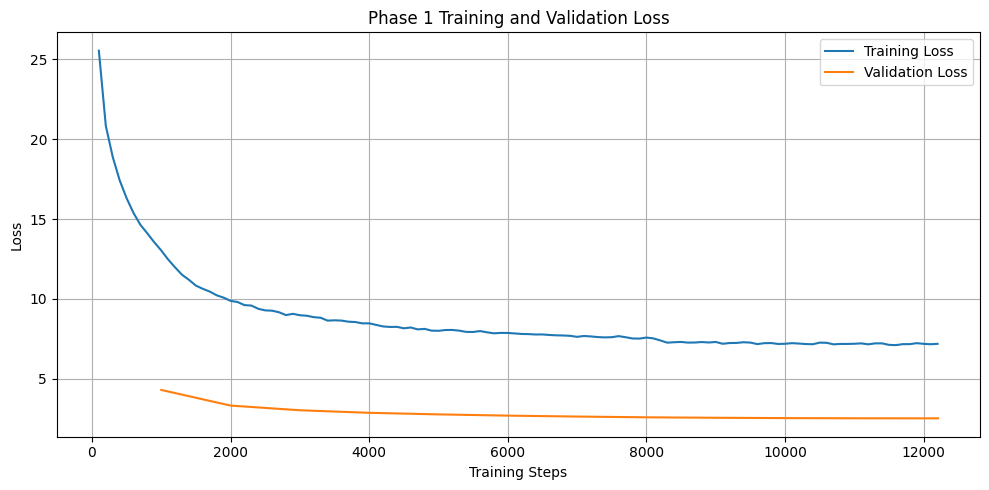

Loss plot saved to:
/kaggle/working/cs781_phase1/training_validation_loss.png


In [27]:
import matplotlib.pyplot as plt

logs = trainer.state.log_history

train_steps = []
train_loss = []
eval_steps = []
eval_loss = []

for log in logs:
    if ("loss" in log and "step" in log):
        train_steps.append(log["step"])
        train_loss.append(log["loss"])
    if ("eval_loss" in log and "step" in log):
        eval_steps.append(log["step"])
        eval_loss.append(log["eval_loss"])

plt.figure(figsize=(10, 5))
plt.plot(train_steps, train_loss, label="Training Loss")
plt.plot(eval_steps, eval_loss, label="Validation Loss")
plt.xlabel("Training Steps")
plt.ylabel("Loss")
plt.title("Phase 1 Training and Validation Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(LOSS_PLOT_PATH, dpi=200)
plt.show()

print("Loss plot saved to:")
print(LOSS_PLOT_PATH)

## 14. Save Final Model to Kaggle Output

In [28]:
trainer.save_model(MODEL_OUTPUT_DIR)
# tokenizer.save_pretrained(MODEL_OUTPUT_DIR)

print("Final model saved to:")
print(MODEL_OUTPUT_DIR)

Final model saved to:
/kaggle/working/cs781_phase1/legal-cnn-attention-final


## 15. Push Model to Hugging Face Hub

In [ ]:
# model.push_to_hub(HF_MODEL_REPO, token=HF_TOKEN)
# tokenizer.push_to_hub(HF_MODEL_REPO, token=HF_TOKEN)

# print("Model and tokenizer pushed successfully.")

## 16. Load Test Data from HuggingFace

In [29]:
from huggingface_hub import hf_hub_download
test_file_path = hf_hub_download(
    repo_id=HF_DATASET_REPO,
    filename=TEST_FILE,
    repo_type="dataset",
    token=HF_TOKEN
)

print("Test file:", test_file_path)

test.json:   0%|          | 0.00/3.03M [00:00<?, ?B/s]

Test file: /root/.cache/huggingface/hub/datasets--Exploration-Lab--CS-781-Capstone/snapshots/89edba6a44d6bb9593fd13b6895b5cd3b06eb82e/Phase_1_Pretraining/Test/test.json


## 17. Load Test Prompts

In [30]:
with open(test_file_path, "r", encoding="utf-8") as f:
    test_data = json.load(f)

print("Number of test examples:", len(test_data))

Number of test examples: 1000


## 18. Load Final Model for Generation

In [50]:
import os
import torch
from safetensors.torch import load_file

MODEL_DIR = "/kaggle/working/cs781_phase1/legal-cnn-attention-final"

generation_model = CNNAttentionLM(
    vocab_size=tokenizer.vocab_size,
    dim=640,
    n_layers=8,
    n_heads=8,
    max_seq_len=2048,
    kernel_size=3,
    ff_mult=4
)

state_dict = load_file(
    os.path.join(MODEL_DIR, "model.safetensors")
)

generation_model.load_state_dict(state_dict)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

generation_model = generation_model.to(device)
generation_model.eval()

print("Model loaded successfully")
print("Device:", next(generation_model.parameters()).device)
print(
    f"Parameters: "
    f"{sum(p.numel() for p in generation_model.parameters()) / 1e6:.2f}M"
)

Model loaded successfully
Device: cuda:0
Parameters: 71.04M


## 19. Generate 128 Words
#### (words, not tokens)

In [59]:
def generate_batch(
    prompts,
    model,
    tokenizer,
    device,
    target_words=128
):
    ans = []

    for prompt in prompts:
        ids = tokenizer.encode(prompt)

        # Keep latest context
        ids = ids[-MODEL_CONTEXT_LENGTH:]

        input_ids = torch.tensor(
            [ids],
            dtype=torch.long,
            device=device
        )

        _, text = custom_generate(
            model=model,
            input_ids=input_ids,
            tokenizer=tokenizer,
            max_new_tokens=384,
            target_words=target_words,
            temperature=0.8,
            top_p=0.9,
            repetition_penalty=1.2,
        )

        text = " ".join(text.split()[:target_words])

        if len(text.split()) != target_words:
            raise RuntimeError(
                f"Expected {target_words} words, "
                f"got {len(text.split())}"
            )

        ans.append(text)

    return ans

## 20. Generate Predictions for the Test Set

In [60]:
import torch
import torch.nn.functional as F


def top_p_sample(logits, temperature=0.8, top_p=0.9):
    logits = logits / max(temperature, 1e-5)

    probs = F.softmax(logits, dim=-1)

    sorted_probs, sorted_idx = torch.sort(
        probs,
        descending=True
    )

    cumulative = torch.cumsum(sorted_probs, dim=-1)

    remove = cumulative > top_p

    # Always retain the highest-probability token
    remove[..., 0] = False

    sorted_probs[remove] = 0.0

    sorted_probs = (
        sorted_probs
        / sorted_probs.sum(dim=-1, keepdim=True)
    )

    sampled_pos = torch.multinomial(
        sorted_probs,
        num_samples=1
    )

    next_token = sorted_idx.gather(
        -1,
        sampled_pos
    )

    return next_token


def custom_generate(
    model,
    input_ids,
    tokenizer,
    max_new_tokens=384,
    target_words=128,
    temperature=0.8,
    top_p=0.9,
    repetition_penalty=1.2,
):
    model.eval()

    generated = input_ids.clone()

    prompt_len = input_ids.shape[1]

    with torch.inference_mode():

        for _ in range(max_new_tokens):

            # Model cannot exceed its context size
            model_input = generated[:, -MODEL_CONTEXT_LENGTH:]

            outputs = model(
                input_ids=model_input
            )

            logits = outputs["logits"][:, -1, :].clone()

            # -----------------------------------
            # Repetition penalty
            # -----------------------------------
            previous_tokens = generated[0].unique()

            token_logits = logits[0, previous_tokens]

            logits[0, previous_tokens] = torch.where(
                token_logits < 0,
                token_logits * repetition_penalty,
                token_logits / repetition_penalty
            )

            # -----------------------------------
            # Don't generate PAD
            # -----------------------------------
            logits[:, PAD_ID] = float("-inf")

            # -----------------------------------
            # Sample next token
            # -----------------------------------
            next_token = top_p_sample(
                logits,
                temperature=temperature,
                top_p=top_p
            )

            generated = torch.cat(
                [generated, next_token],
                dim=1
            )

            # Only decode the continuation
            new_tokens = generated[0, prompt_len:].tolist()

            text = tokenizer.decode(new_tokens)

            words = text.split()

            # We need exactly 128 words
            if len(words) >= target_words:
                break

    new_tokens = generated[0, prompt_len:].tolist()

    text = tokenizer.decode(new_tokens)

    # Exactly 128 words
    text = " ".join(
        text.split()[:target_words]
    )

    return generated, text

In [52]:
example_id = list(test_data.keys())[99]
test_prompt = test_data[example_id]["text"]

encoded = tokenizer.encode(test_prompt)

# Keep room for generation
encoded = encoded[-MODEL_CONTEXT_LENGTH:]

input_ids = torch.tensor(
    [encoded],
    dtype=torch.long,
    device=device
)

print("Prompt tokens:", input_ids.shape[1])

test_output, generated_text = custom_generate(
    model=generation_model,
    input_ids=input_ids,
    tokenizer=tokenizer,
    max_new_tokens=384,
    target_words=128,
    temperature=0.8,
    top_p=0.9,
    repetition_penalty=1.2,
)

new_tokens = test_output[
    0,
    input_ids.shape[1]:
].tolist()

print("\nGenerated token IDs:", new_tokens[:30])
print("\nGenerated new tokens:", len(new_tokens))
print("\nGenerated text:")
print(repr(generated_text))
print("\nGenerated words:", len(generated_text.split()))

Prompt tokens: 563

Generated token IDs: [273, 265, 10557, 273, 3423, 4070, 281, 265, 12597, 11734, 2278, 287, 265, 4554, 827, 4072, 299, 12881, 121, 324, 413, 1825, 265, 1257, 273, 8623, 293, 95, 547, 1509]

Generated new tokens: 142

Generated text:
'of the saving of laws enacted on the Seventh Schedule to the Constitution. This interpretation is plausible because the effect of amendments in [Section 161] is to remove obstacles with retrospective operation envisaged therein. Similarly, Section 17 refers to the situation where some other legislators have been appointed together, but nothing has been done in such a way since that some legislature has chosen to introduce that there was no legislative intent on the democratic set up. 26. As regards the claim made by respondent No. 1 that after the enactment of Section 174 the Government had decided to provide for the appointment of a Chairperson and a Member thereof. This amendment has come into force w.e.f. 1st January, 1977. 27. By vir

In [62]:
predictions = {}
GENERATION_BATCH_SIZE = 32

items = list(test_data.items())
total_examples = len(items)

print(f"Total test examples: {total_examples}")

start_from = len(predictions)

print("Already completed:", start_from)

for start in range(
    start_from,
    total_examples,
    GENERATION_BATCH_SIZE
):
    batch = items[start:start + GENERATION_BATCH_SIZE]

    batch_ids = [
        str(example_id)
        for example_id, _ in batch
    ]

    batch_prompts = [
        record["text"]
        for _, record in batch
    ]

    batch_predictions = generate_batch(
        prompts=batch_prompts,
        model=generation_model,
        tokenizer=tokenizer,
        device=device,
        target_words=128
    )

    if len(batch_predictions) != len(batch_ids):
        raise RuntimeError(
            f"Expected {len(batch_ids)} predictions, "
            f"received {len(batch_predictions)}"
        )

    for example_id, prediction in zip(
        batch_ids,
        batch_predictions
    ):
        predictions[example_id] = {
            "text": prediction
        }

    completed = start + len(batch)

    print(
        f"Completed {completed}/{total_examples} "
        f"({100 * completed / total_examples:.1f}%)"
    )

Total test examples: 1000
Already completed: 0
Completed 32/1000 (3.2%)
Completed 64/1000 (6.4%)
Completed 96/1000 (9.6%)
Completed 128/1000 (12.8%)
Completed 160/1000 (16.0%)
Completed 192/1000 (19.2%)
Completed 224/1000 (22.4%)
Completed 256/1000 (25.6%)
Completed 288/1000 (28.8%)
Completed 320/1000 (32.0%)
Completed 352/1000 (35.2%)
Completed 384/1000 (38.4%)
Completed 416/1000 (41.6%)
Completed 448/1000 (44.8%)
Completed 480/1000 (48.0%)
Completed 512/1000 (51.2%)
Completed 544/1000 (54.4%)
Completed 576/1000 (57.6%)
Completed 608/1000 (60.8%)
Completed 640/1000 (64.0%)
Completed 672/1000 (67.2%)
Completed 704/1000 (70.4%)
Completed 736/1000 (73.6%)
Completed 768/1000 (76.8%)
Completed 800/1000 (80.0%)
Completed 832/1000 (83.2%)
Completed 864/1000 (86.4%)
Completed 896/1000 (89.6%)
Completed 928/1000 (92.8%)
Completed 960/1000 (96.0%)
Completed 992/1000 (99.2%)
Completed 1000/1000 (100.0%)


## 21. Save prediction.json

In [63]:
with open(PREDICTION_PATH, "w", encoding="utf-8") as f:
    json.dump(
        predictions,
        f,
        ensure_ascii=False,
        indent=2
    )

print("prediction.json saved:")
print(PREDICTION_PATH)

prediction.json saved:
/kaggle/working/cs781_phase1/prediction.json


## 22. Create CodaBench Submission ZIP

In [64]:
with zipfile.ZipFile(SUBMISSION_ZIP, "w", compression=zipfile.ZIP_DEFLATED) as zipf:
    zipf.write(PREDICTION_PATH, arcname="prediction.json")

print("Codabench submission created:")
print(SUBMISSION_ZIP)

Codabench submission created:
/kaggle/working/cs781_phase1/submission.zip
